# FastSpeech 2 text-to-speech - English (Svarah)

This notebook trains a multi-speaker FastSpeech 2 text-to-speech model for English, using the PyTorch implementation
[ming024/FastSpeech2](https://github.com/ming024/FastSpeech2) with the modifications described in the project README.
It covers the full pipeline: data selection, pronunciation lexicon, forced alignment, feature extraction, training,
inference on the five test sentences, and the variance-adaptor plots (duration, pitch, energy).

**Data:** [Svarah](https://huggingface.co/datasets/ai4bharat/Svarah) (`ai4bharat/Svarah`), 9.6 h of Indian-accented English from 117 speakers (read and conversational speech).

**Runtime.** Data preparation (sections 2-11) runs on CPU; training (sections 13-15) needs a GPU. The notebook can be run
with *Runtime -> Run all*: stages that are already complete are skipped, and a stage that fails stops the run.
If the runtime has no GPU, execution stops before training with a message; switching the runtime type to a T4 GPU and
running all cells again continues from there. Prepared data and checkpoints are kept on Google Drive, so a disconnected
session can resume.

**Version 2 (this notebook).** The first run (version 1, 30,000 steps) overfitted: the validation loss reached its minimum very early while the audio kept improving, and the pitch and energy losses on the training set were far below those on the validation set. This version changes the training recipe only; data, alignment and features are the same as in version 1:
- a shorter schedule (15,000 steps) with the learning rate reduced earlier (steps 8000, 11000, 13000);
- AdamW optimiser with decoupled weight decay 0.01 (version 1 used Adam without weight decay); a first attempt with ordinary L2 weight decay 0.01 and dropout 0.3 stopped the model from learning (training loss rose after step 1500) and was abandoned;
- a snapshot of the weights every 1000 steps instead of only "best" and "last";
- the final checkpoint is chosen by objective measurements on the validation set (section 14b) instead of the validation loss.

## 1. Environment
Checks for a GPU and defines two small helpers: `sh()` runs a shell command and raises on failure, `have()` tests whether files exist.

In [1]:
!nvidia-smi -L || echo 'No GPU in this session'

import os, glob, subprocess, shutil, zipfile

def sh(cmd):
    # run a shell command, stream its output, and raise if it fails
    p = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                         text=True, bufsize=1, executable='/bin/bash')
    out = []
    for line in p.stdout:
        print(line, end=''); out.append(line)
    if p.wait() != 0:
        raise RuntimeError('Command failed (exit code %d) - see the output above.' % p.returncode)
    return ''.join(out)

def have(pattern):
    return len(glob.glob(pattern)) > 0

os.environ['FS2_WORK'] = '/content/work'
print('helpers ready')

GPU 0: Tesla T4 (UUID: GPU-4f80b380-ca8f-7407-55d0-ff2abf6bd29f)
helpers ready


## 2. Project code
Mounts Google Drive and unpacks `project.zip` (the code, configuration files and pretrained HiFi-GAN vocoder). Prepared data and checkpoints are stored in `fs2_english/` on Drive.

In [2]:
from google.colab import drive
drive.mount('/content/drive')
os.chdir('/content')
shutil.rmtree('/content/project', ignore_errors=True)
zipfile.ZipFile('/content/drive/MyDrive/project.zip').extractall('/content')
os.chdir('/content/project')
os.makedirs('/content/drive/MyDrive/fs2_english', exist_ok=True)
PREP_TAR = '/content/drive/MyDrive/fs2_english/prepared_data.tar'
print('code ready:', os.listdir('/content/project'))

Mounted at /content/drive
code ready: ['Results', 'README.md', 'English', 'tests', 'requirements.txt', 'Telugu', '.gitignore', 'common', 'notebooks', 'Report', 'fastspeech2']


## 3. Python dependencies
Installs the audio, alignment-file and text-processing packages; PyTorch is already part of the Colab image. NLTK data is needed by the grapheme-to-phoneme tool.

In [3]:
sh('pip install -q pyworld tgt g2p-en inflect soundfile librosa pyyaml scikit-learn matplotlib datasets unidecode')
import nltk
for p in ['averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng', 'cmudict']:
    nltk.download(p, quiet=True)
print('ok')

ok


## 4. Montreal Forced Aligner
FastSpeech 2 needs the duration of every phone, which comes from forced alignment of each recording against its transcript.
The Montreal Forced Aligner (MFA) is installed with micromamba in its own environment so it does not interfere with the
Python packages above. The step is skipped when prepared data already exists on Drive.

In [6]:
if os.path.exists(PREP_TAR):
    print('prepared data found on Drive - aligner not needed')
else:
    sh('''
    set -e
    export MAMBA_ROOT_PREFIX=$HOME/micromamba
    if [ ! -f $MAMBA_ROOT_PREFIX/bin/micromamba ]; then
      mkdir -p $MAMBA_ROOT_PREFIX/bin
      curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xj -C $MAMBA_ROOT_PREFIX bin/micromamba
    fi
    if [ ! -d $MAMBA_ROOT_PREFIX/envs/mfa ]; then
      $MAMBA_ROOT_PREFIX/bin/micromamba create -y -n mfa -c conda-forge python=3.11 montreal-forced-aligner
    fi
    $MAMBA_ROOT_PREFIX/bin/micromamba run -n mfa mfa version
    ''')

prepared data found on Drive - aligner not needed


## 5. Hugging Face access
1. Create a Hugging Face account (or log in).
2. Open https://huggingface.co/datasets/ai4bharat/Svarah and accept the dataset conditions (*Agree and access repository*) - the dataset is gated.
3. Create a read token at https://huggingface.co/settings/tokens (*Create new token* -> type **Read**) and paste it in the prompt below.

The token is read through a hidden prompt and is not stored in the notebook.

In [7]:
from getpass import getpass
if os.path.exists(PREP_TAR):
    print('prepared data found on Drive - token not needed')
elif not os.environ.get('HF_TOKEN'):
    os.environ['HF_TOKEN'] = getpass('Hugging Face token: ')
    print('token received, length', len(os.environ['HF_TOKEN']))

prepared data found on Drive - token not needed


## 6. Restore previously prepared data
If a previous session already finished sections 7-10, the prepared data is restored from Drive and those stages are skipped.

In [8]:
tar = PREP_TAR
if not have('/content/work/preprocessed_data/*/train.txt') and os.path.exists(tar):
    os.makedirs('/content/work', exist_ok=True)
    sh('tar -xf ' + tar + ' -C /content')
    print('restored prepared data from Drive')
else:
    print('nothing to restore')

restored prepared data from Drive


## 7. Data selection
Svarah has no speaker-ID column, so speakers are approximated by the unique combinations of the speaker metadata columns (gender, age group, native language and place, qualification, occupation); every pseudo-speaker contributes the same fraction of its audio.
Clips shorter than 1 s or longer than the limit set in `config.yaml` are dropped, and the selected clips are split by
utterance into training (~5 h) and validation (~1 h) sets, so no clip appears in both. Audio is resampled to 22.05 kHz mono and
the transcripts are normalised. The per-speaker statistics are written to `selection_stats.json`.

In [9]:
if have('/content/work/preprocessed_data/*/train.txt'):
    print('data already prepared - skipping')
elif have('/content/work/raw_data/*/split.json'):
    print('data already downloaded - skipping')
else:
    sh('python English/preprocess.py --stage select')

data already prepared - skipping


In [10]:
sh('cat /content/work/raw_data/*/selection_stats.json | head -40')

{
  "train_hours": 4.98638138888889,
  "val_hours": 1.1090703819444445,
  "train_utterances": 3452,
  "val_utterances": 748,
  "n_speakers": 103,
  "dropped": {
    "too short": 1215,
    "too long": 486
  },
  "pseudo_speaker_columns": [
    "gender",
    "age-group",
    "primary_language",
    "native_place_state",
    "native_place_district",
    "highest_qualification",
    "job_category",
    "occupation_domain"
  ],
  "pseudo_speaker_keys": {
    "spk000": [
      "Female",
      "18-30",
      "Kannada",
      "Karnataka",
      "Hassan",
      "Post Graduate",
      "Full Time",
      "Technology and Services"
    ],
    "spk001": [
      "Female",
      "30-45",
      "Kannada",
      "Karnataka",
      "Gulbarga",
      "Post Graduate",
      "Full Time",
      "Technology and Services"


'{\n  "train_hours": 4.98638138888889,\n  "val_hours": 1.1090703819444445,\n  "train_utterances": 3452,\n  "val_utterances": 748,\n  "n_speakers": 103,\n  "dropped": {\n    "too short": 1215,\n    "too long": 486\n  },\n  "pseudo_speaker_columns": [\n    "gender",\n    "age-group",\n    "primary_language",\n    "native_place_state",\n    "native_place_district",\n    "highest_qualification",\n    "job_category",\n    "occupation_domain"\n  ],\n  "pseudo_speaker_keys": {\n    "spk000": [\n      "Female",\n      "18-30",\n      "Kannada",\n      "Karnataka",\n      "Hassan",\n      "Post Graduate",\n      "Full Time",\n      "Technology and Services"\n    ],\n    "spk001": [\n      "Female",\n      "30-45",\n      "Kannada",\n      "Karnataka",\n      "Gulbarga",\n      "Post Graduate",\n      "Full Time",\n      "Technology and Services"\n'

## 8. Pronunciation lexicon and forced alignment
The lexicon maps every word of the selected transcripts to phones. The aligner is then trained on the selected data and writes
one phone-level TextGrid per utterance. Recipe: MFA's full training pipeline (monophone, triphone, LDA-MLLT and speaker-adaptive stages), the same recipe for both languages so the results are comparable; this is the slowest preparation step (a few hours on CPU). Utterances the aligner cannot align are reported and excluded.

In [11]:
if have('/content/work/preprocessed_data/*/train.txt'):
    print('data already prepared - skipping')
else:
    sh('python English/preprocess.py --stage lexicon')
    if have('/content/work/preprocessed_data/*/TextGrid/*/*.TextGrid'):
        print('alignment already done - skipping')
    else:
        sh('python English/preprocess.py --stage align --num_jobs 4')

data already prepared - skipping


## 9. Feature extraction
Computes mel-spectrograms, phoneme-level pitch (F0) and energy, and durations from the alignments. Pitch and energy statistics for normalisation are fitted on the training files only.

In [12]:
if not have('/content/work/preprocessed_data/*/train.txt'):
    sh('python English/preprocess.py --stage features')
sh('cat /content/work/preprocessed_data/*/preprocess_summary.json')

{
  "train": {
    "utterances": 3437,
    "hours": 3.689,
    "speakers": 103
  },
  "val": {
    "utterances": 744,
    "hours": 0.816,
    "speakers": 103
  }
}

'{\n  "train": {\n    "utterances": 3437,\n    "hours": 3.689,\n    "speakers": 103\n  },\n  "val": {\n    "utterances": 744,\n    "hours": 0.816,\n    "speakers": 103\n  }\n}'

## 10. Back up the prepared data
Archives the prepared data to Drive so that a later session can skip sections 7-9.

In [13]:
import tarfile
files = ['work/preprocessed_data', 'work/lexicon.txt']
for pat in ('split.json', 'selection_stats.json'):
    files += [os.path.relpath(p, '/content') for p in glob.glob('/content/work/raw_data/*/' + pat)]
tmp = '/content/drive/MyDrive/fs2_english/prepared_data.tar.part'
with tarfile.open(tmp, 'w') as t:
    for f in files:
        t.add('/content/' + f, arcname=f)
os.replace(tmp, '/content/drive/MyDrive/fs2_english/prepared_data.tar')
sh('ls -lh /content/drive/MyDrive/fs2_english/')

total 498M
-rw------- 1 root root 498M Nov  5 15:38 prepared_data.tar


'total 498M\n-rw------- 1 root root 498M Nov  5 15:38 prepared_data.tar\n'

## 11. Sanity check
Plays a few of the selected recordings with their transcripts.

In [14]:
import IPython.display as ipd
for w in sorted(glob.glob('/content/work/raw_data/*/*/*.wav'))[::700][:4]:
    print(w); print(open(w[:-4] + '.lab', encoding='utf-8').read()); ipd.display(ipd.Audio(w))

## 12. GPU check
Training requires a GPU. If the session has none, execution stops here; the prepared data is already saved.

In [15]:
import torch
if not torch.cuda.is_available():
    raise RuntimeError('Data preparation is complete and saved to Drive. No GPU in this session, so stopping before training. '
                       'Switch the runtime type to a T4 GPU (Runtime > Change runtime type) and run all cells again; completed stages are skipped.')
print('GPU available:', torch.cuda.get_device_name(0))

GPU available: Tesla T4


## 13. Smoke test
Runs 30 training steps and one validation pass to confirm that the data, model and loss are wired up correctly. Skipped when a training run already exists.

In [16]:
if os.path.exists('/content/drive/MyDrive/fs2_english/ckpt/resume.pth.tar'):
    print('training already started earlier - skipping the smoke test')
else:
    shutil.rmtree('/content/work/ckpt', ignore_errors=True); shutil.rmtree('/content/work/log', ignore_errors=True)
    sh('python English/train.py --total_step 30 --plots_dir /tmp/testplots')
    shutil.rmtree('/content/work/ckpt', ignore_errors=True); shutil.rmtree('/content/work/log', ignore_errors=True)

parameters: 35.1 M, device: cuda
starting from scratch
VALIDATION step 30  total 9.783 (mel 3.792 postnet 2.148 pitch 1.207 energy 1.182 dur 1.454)
  new best validation loss -> best_model_fp16.pth
saved checkpoint at step 30 (final)
finished at step 30
no /content/work/log/train_loss.csv
wrote /tmp/testplots/validation_loss.png


## 14. Training
15,000 steps (shortened schedule, learning rate annealed earlier, AdamW weight decay 0.01), batch size 16 (see `config.yaml`). Losses are logged to CSV every 50 steps and the validation loss is computed on the full
validation set every 500 steps. Checkpoints go to Drive and the run resumes automatically; the cell stops after 170 minutes
to stay within the Colab session limit and can simply be run again to continue. A snapshot of the weights is also kept every 1000 steps in `ckpt/snapshots/`; the final checkpoint is chosen in the next section from objective measurements, because the validation loss turned out to be a poor guide (see the report).

In [17]:
import re
for d in ('ckpt', 'log'):
    target = '/content/drive/MyDrive/fs2_english/' + d
    os.makedirs(target, exist_ok=True)
    link = '/content/work/' + d
    if not os.path.islink(link):
        if os.path.exists(link):
            shutil.rmtree(link)
        os.symlink(target, link)
out = sh('python English/train.py --max_minutes 170')
m = re.findall(r'finished at step (\d+)', out)
TOTAL = 15000
if not m or int(m[-1]) < TOTAL:
    raise RuntimeError('Training paused at step %s of %d (session time limit). Re-run this cell to resume.' % (m[-1] if m else '?', TOTAL))
print('training finished')

parameters: 35.1 M, device: cuda
starting from scratch
step 50/15000  loss 12.892 (mel 4.124 postnet 3.839 pitch 1.632 energy 1.638 dur 1.659)
step 100/15000  loss 8.778 (mel 3.185 postnet 2.716 pitch 1.021 energy 1.329 dur 0.527)
step 150/15000  loss 6.187 (mel 2.109 postnet 1.829 pitch 0.739 energy 1.124 dur 0.386)
step 200/15000  loss 4.875 (mel 1.401 postnet 1.399 pitch 0.674 energy 1.059 dur 0.341)
step 250/15000  loss 4.475 (mel 1.215 postnet 1.317 pitch 0.649 energy 0.983 dur 0.310)
step 300/15000  loss 4.256 (mel 1.162 postnet 1.290 pitch 0.591 energy 0.938 dur 0.276)
step 350/15000  loss 4.132 (mel 1.119 postnet 1.249 pitch 0.600 energy 0.915 dur 0.249)
step 400/15000  loss 4.019 (mel 1.092 postnet 1.207 pitch 0.593 energy 0.892 dur 0.235)
step 450/15000  loss 3.948 (mel 1.076 postnet 1.202 pitch 0.565 energy 0.872 dur 0.234)
step 500/15000  loss 3.836 (mel 1.046 postnet 1.155 pitch 0.546 energy 0.864 dur 0.226)
VALIDATION step 500  total 3.655 (mel 1.032 postnet 1.046 pitch 0

## 14b. Checkpoint selection
Every snapshot is evaluated on held-out validation sentences without listening: how close the generated mel-spectrogram is to the real one (after time alignment), duration error, speaking-rate ratio, and how well predicted pitch and energy follow the real ones. The checkpoint with the smallest spectrogram distance is used for all results below.

In [18]:
r = subprocess.run(['python', '/content/project/common/evaluate_snapshots.py',
    '--lang_dir', '/content/project/English', '--ckpt_dir', '/content/work/ckpt',
    '--out_dir', '/content/project/Results/English/extra/checkpoint_selection'], capture_output=True, text=True)
print(r.stdout[-5000:]); print(r.stderr[-1500:])

evaluating 17 checkpoints on 160 validation utterances
step 1000  mel_dist 11.868 | dur_mae 2.69 | rate 0.95 | pitch r 0.28 rmse 0.55 | energy r 0.40 rmse 0.87
step 2000  mel_dist 11.558 | dur_mae 2.73 | rate 0.94 | pitch r 0.29 rmse 0.59 | energy r 0.39 rmse 0.89
step 3000  mel_dist 11.569 | dur_mae 2.74 | rate 0.90 | pitch r 0.30 rmse 0.55 | energy r 0.40 rmse 0.90
step 4000  mel_dist 11.320 | dur_mae 2.74 | rate 0.84 | pitch r 0.30 rmse 0.55 | energy r 0.40 rmse 0.87
step 5000  mel_dist 11.176 | dur_mae 2.73 | rate 1.01 | pitch r 0.29 rmse 0.55 | energy r 0.41 rmse 0.86
step 6000  mel_dist 11.207 | dur_mae 2.67 | rate 0.92 | pitch r 0.28 rmse 0.58 | energy r 0.41 rmse 0.87
step 7000  mel_dist 11.317 | dur_mae 2.67 | rate 0.92 | pitch r 0.27 rmse 0.57 | energy r 0.39 rmse 0.90
step 8000  mel_dist 11.243 | dur_mae 2.67 | rate 0.96 | pitch r 0.27 rmse 0.59 | energy r 0.40 rmse 0.90
step 9000  mel_dist 11.299 | dur_mae 2.60 | rate 0.93 | pitch r 0.26 rmse 0.58 | energy r 0.40 rmse 0.89


In [ ]:
import json
sel = json.load(open('/content/project/Results/English/extra/checkpoint_selection/selected.json'))['selected']
SEL = '/content/work/ckpt/' + ('snapshots/step_%s_fp16.pth' % sel.split()[1] if sel.startswith('step') else sel + '_model_fp16.pth')
print('selected:', sel, '->', SEL)

## 15. Inference and plots
Synthesises the five test sentences with the selected checkpoint and saves the audio, the predicted duration / pitch (F0) / energy
per phone for each sentence, the mel-spectrograms, and the training and validation loss curves to `Results/English/`.

In [20]:
sh('python English/inference.py --checkpoint ' + SEL + ' --all_speakers')
sh('python English/train.py --plots_only --plots_dir /content/project/Results/English')

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
checkpoint: /content/work/ckpt/snapshots/step_5000_fp16.pth
Removing weight norm...
main speaker: spk013 (id 13); 103 speakers in model
E1: 87 phones, 5.97 s
E2a: 51 phones, 3.88 s
E2b: 56 phones, 4.10 s
E3: 37 phones, 2.72 s
E4: 81 phones, 6.12 s
done. audio -> /content/project/Results/English/test_generated_audios | plots -> /content/project/Results/English/variance_adaptor_plots
wrote /content/project/Results/English/training_loss.png
wrote /content/project/Results/English/validation_loss.png


'wrote /content/project/Results/English/training_loss.png\nwrote /content/project/Results/English/validation_loss.png\n'

In [28]:
import IPython.display as ipd
for w in sorted(glob.glob('/content/project/Results/English/test_generated_audios/*.wav')):
    print(w.split('/')[-1]); ipd.display(ipd.Audio(w))

E1.wav


E2a.wav


E2b.wav


E3.wav


E4.wav


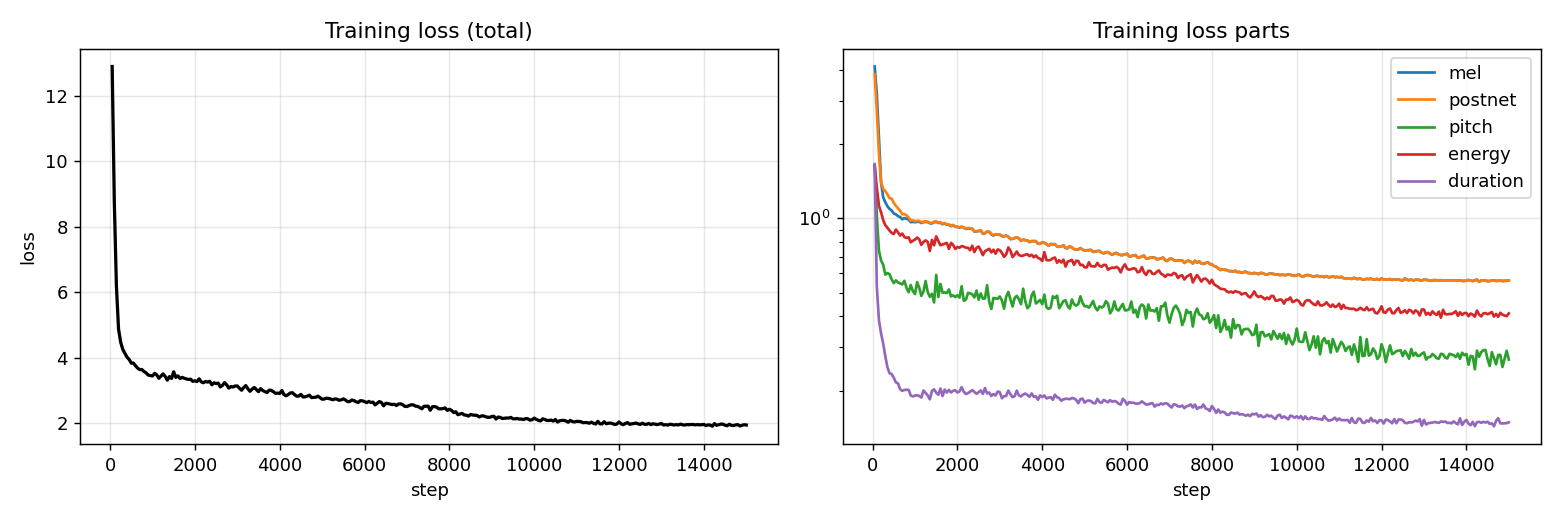

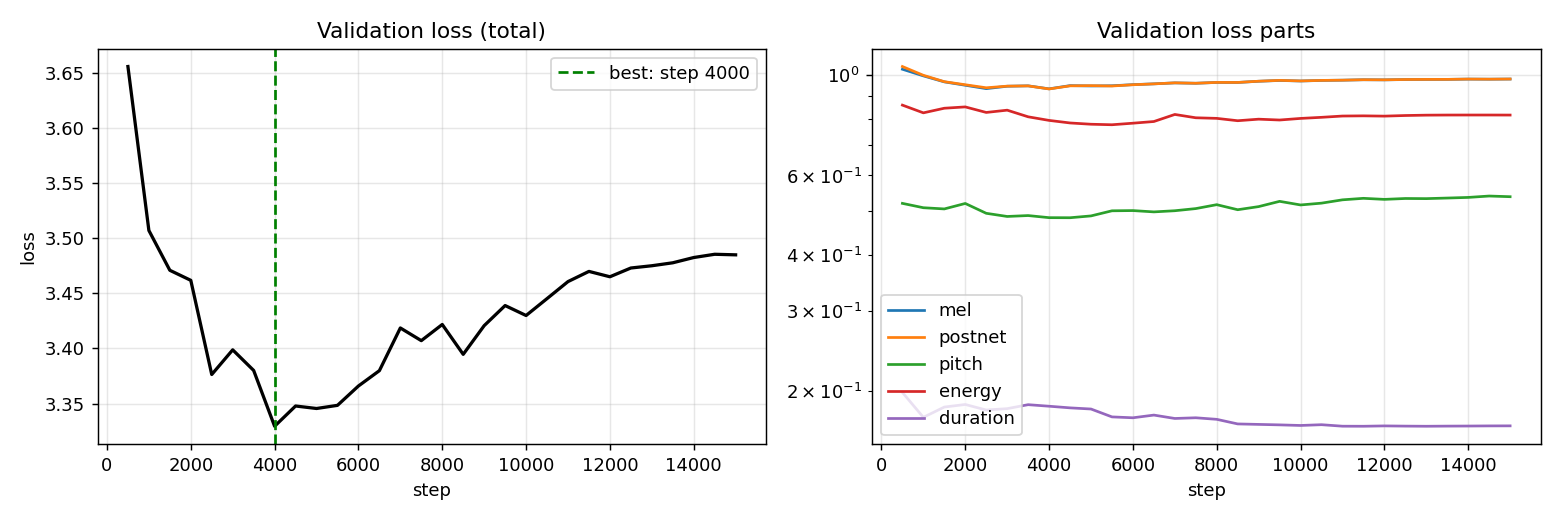

In [29]:
from IPython.display import Image, display
for p in ['training_loss.png', 'validation_loss.png']:
    display(Image('/content/project/Results/English/' + p))

## 16. Additional experiments
Two ablations on the English front end:
1. **Context-aware vs. dictionary pronunciation.** `g2p_en` run on the whole sentence can assign different stress to heteronyms
   (noun vs. verb *conduct*, E2a / E2b); plain word-by-word lexicon lookup cannot.
2. **Number / time normalisation off** for E4 (*10:45 AM, 12 November 2026*). `g2p_en` expands digits on its own, so the difference may be small.

In [30]:
sh('python English/inference.py --checkpoint ' + SEL + ' --g2p_mode lexicon --out_dir /content/project/Results/English/extra/plain_dictionary')
sh('python English/inference.py --checkpoint ' + SEL + ' --no_normalize --out_dir /content/project/Results/English/extra/no_normalisation')

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
checkpoint: /content/work/ckpt/snapshots/step_5000_fp16.pth
Removing weight norm...
main speaker: spk013 (id 13); 103 speakers in model
E1: 85 phones, 5.82 s
E2a: 50 phones, 3.78 s
E2b: 56 phones, 4.04 s
E3: 37 phones, 2.71 s
E4: 79 phones, 5.94 s
done. audio -> /content/project/Results/English/extra/plain_dictionary/test_generated_audios | plots -> /content/project/Results/English/extra/plain_dictionary/variance_adaptor_plots
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
checkpoint: /content/work/ckpt/snapshots/step_5000_fp16.pth
Removing weight norm...
main speaker: spk013 (id 

'/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.\n  WeightNorm.apply(module, name, dim)\ncheckpoint: /content/work/ckpt/snapshots/step_5000_fp16.pth\nRemoving weight norm...\nmain speaker: spk013 (id 13); 103 speakers in model\nE1: 87 phones, 5.97 s\nE2a: 51 phones, 3.88 s\nE2b: 56 phones, 4.10 s\nE3: 37 phones, 2.72 s\nE4: 79 phones, 6.16 s\ndone. audio -> /content/project/Results/English/extra/no_normalisation/test_generated_audios | plots -> /content/project/Results/English/extra/no_normalisation/variance_adaptor_plots\n'

## 17. Export
Copies the checkpoints (fp16 weights, ~70 MB each), the dataset statistics and the loss logs next to the results, and writes two archives to Drive.

In [31]:
os.makedirs('/content/project/English/checkpoints', exist_ok=True)
for f in ('best_model_fp16.pth', 'last_model_fp16.pth'):
    shutil.copy('/content/drive/MyDrive/fs2_english/ckpt/' + f, '/content/project/English/checkpoints/' + f)
for f in glob.glob('/content/work/preprocessed_data/*/preprocess_summary.json') + glob.glob('/content/work/raw_data/*/selection_stats.json'):
    shutil.copy(f, '/content/project/Results/English/')
shutil.copy('/content/work/log/train_loss.csv', '/content/project/Results/English/')
shutil.copy('/content/work/log/val_loss.csv', '/content/project/Results/English/')
shutil.make_archive('/content/drive/MyDrive/English_results', 'zip', '/content/project', 'Results/English')
shutil.make_archive('/content/drive/MyDrive/English_checkpoints', 'zip', '/content/project', 'English/checkpoints')
print('saved: English_results.zip and English_checkpoints.zip (in My Drive)')

saved: English_results.zip and English_checkpoints.zip (in My Drive)


## 18. Reference recordings
A few real recordings from the training and validation sets, rebuilt from their stored spectrograms through the vocoder. This is the quality and style of speech the model is trying to reproduce.

In [32]:
import os, sys, torch, IPython.display as ipd
os.chdir('/content/project'); sys.path.insert(0, '/content/project')
from common.configio import load_config, setup_paths
setup_paths()
from torch.utils.data import DataLoader
cfg, configs = load_config('/content/project/English/config.yaml')
pre, mod, tr = configs
from dataset import Dataset
from utils.model import get_vocoder, vocoder_infer
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
voc = get_vocoder(mod, dev)
sr = pre['preprocessing']['audio']['sampling_rate']
hop = pre['preprocessing']['stft']['hop_length']
for split in ('train', 'val'):
    ds = Dataset(split + '.txt', pre, tr, sort=False, drop_last=False)
    loader = DataLoader(ds, batch_size=8, shuffle=True, collate_fn=ds.collate_fn)
    ids, raw, spk, texts, src_lens, max_src, mels, mel_lens, *_ = next(iter(loader))[0]
    print('=====', split, 'set')
    for i in range(3):
        T = int(mel_lens[i])
        w = vocoder_infer(torch.from_numpy(mels[i, :T]).float().unsqueeze(0).transpose(1, 2).to(dev), voc, mod, pre, lengths=[T * hop])[0]
        print(raw[i]); ipd.display(ipd.Audio(w, rate=sr))

Removing weight norm...
===== train set
learning opportunities related to interests and subjects that are motivating


cashew processing has also been a traditional industry in the state.


so it is little difficult to roll those rotis as it doesn't have any gluten


===== val set
i find ariel detergent washing powder more expensive than other shops


the answer is ajit, varsha, vedang, shailesh, omkar.


the price mentioned for national gardens potted tomato seeds is not correct as compare to market prices.


## 19. Real recording vs generated speech
Five held-out validation sentences (never used for training). Each is played first as the real recording, then as the speech the model generates from the text alone, using the checkpoint chosen in section 14b.

In [33]:
from model import FastSpeech2
from utils.tools import to_device
from common import synth
model = FastSpeech2(pre, mod).to(dev); synth.load_weights(model, SEL, dev)
ds = Dataset('val.txt', pre, tr, sort=False, drop_last=False)
loader = DataLoader(ds, batch_size=8, shuffle=False, collate_fn=ds.collate_fn)
batch = to_device(next(iter(loader))[0], dev)
ids, raw, spk, texts, src_lens, max_src, mels, mel_lens, *_ = batch
def wav(mel, frames):
    return vocoder_infer(mel.unsqueeze(0).transpose(1, 2), voc, mod, pre, lengths=[frames * hop])[0]
for i in range(5):
    T, L = int(mel_lens[i]), int(src_lens[i])
    with torch.no_grad():
        pr = model(spk[i:i+1], texts[i:i+1, :L], src_lens[i:i+1], L)
    pm = int(pr[9][0])
    print(raw[i])
    print('REAL recording:'); ipd.display(ipd.Audio(wav(mels[i, :T], T), rate=sr))
    print('MODEL generated:'); ipd.display(ipd.Audio(wav(pr[1][0, :pm], pm), rate=sr))

he grew up under the influence of the hindi film industry.
REAL recording:


MODEL generated:


also music has a very
REAL recording:


MODEL generated:


and after worshipping, i sun-dry these flowers
REAL recording:


MODEL generated:


so that we could use them as medicines
REAL recording:


MODEL generated:


lower middle class, backward classes, farmers, and other economically weaker sections of the societies are availed various subsidies and health insurances by the government.
REAL recording:


MODEL generated:


## 20. Export of the version 2 results
Adds the checkpoint selected in section 14b to the checkpoints folder and writes the version 2 archives to Drive, named separately from the version 1 archives.

In [34]:
import shutil
shutil.copy(SEL, '/content/project/English/checkpoints/selected_model_fp16.pth')
shutil.make_archive('/content/drive/MyDrive/English_v2_checkpoints', 'zip', '/content/project', 'English/checkpoints')
shutil.make_archive('/content/drive/MyDrive/English_v2_results', 'zip', '/content/project', 'Results/English')
print(os.listdir('/content/project/English/checkpoints'))
print('saved English_v2_checkpoints.zip and English_v2_results.zip')


['last_model_fp16.pth', 'best_model_fp16.pth', 'selected_model_fp16.pth']
saved English_v2_checkpoints.zip and English_v2_results.zip


In [37]:
STEP = 2000
CK = f'/content/work/ckpt/snapshots/step_{STEP}_fp16.pth'
out = f'/content/project/Results/English/extra/try_step_{STEP}'
sh(f'python English/inference.py --checkpoint {CK} --out_dir {out}')
for w in sorted(glob.glob(out + '/*.wav')):
    print(w.split('/')[-1]); ipd.display(ipd.Audio(w))

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
checkpoint: /content/work/ckpt/snapshots/step_2000_fp16.pth
Removing weight norm...
main speaker: spk013 (id 13); 103 speakers in model
E1: 87 phones, 6.14 s
E2a: 51 phones, 3.68 s
E2b: 56 phones, 3.95 s
E3: 37 phones, 2.62 s
E4: 81 phones, 5.64 s
done. audio -> /content/project/Results/English/extra/try_step_2000/test_generated_audios | plots -> /content/project/Results/English/extra/try_step_2000/variance_adaptor_plots


In [38]:
for STEP in (2000, 15000):
    d = f'/content/project/Results/English/extra/try_step_{STEP}/test_generated_audios'
    print('=====', 'step', STEP)
    for w in sorted(glob.glob(d + '/*.wav')):
        print(w.split('/')[-1]); ipd.display(ipd.Audio(w))

===== step 2000
E1.wav


E2a.wav


E2b.wav


E3.wav


E4.wav


===== step 15000
E1.wav


E2a.wav


E2b.wav


E3.wav


E4.wav


In [36]:
STEP = 15000
CK = f'/content/work/ckpt/snapshots/step_{STEP}_fp16.pth'
out = f'/content/project/Results/English/extra/try_step_{STEP}'
sh(f'python English/inference.py --checkpoint {CK} --out_dir {out}')
for w in sorted(glob.glob(out + '/*.wav')):
    print(w.split('/')[-1]); ipd.display(ipd.Audio(w))

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
checkpoint: /content/work/ckpt/snapshots/step_15000_fp16.pth
Removing weight norm...
main speaker: spk013 (id 13); 103 speakers in model
E1: 87 phones, 5.51 s
E2a: 51 phones, 3.58 s
E2b: 56 phones, 3.76 s
E3: 37 phones, 2.60 s
E4: 81 phones, 5.86 s
done. audio -> /content/project/Results/English/extra/try_step_15000/test_generated_audios | plots -> /content/project/Results/English/extra/try_step_15000/variance_adaptor_plots


In [39]:
import os, shutil, glob
R = '/content/project/Results/English'
keep = R + '/extra/objective_pick_step5000'
os.makedirs(keep, exist_ok=True)
for sub in ('test_generated_audios', 'variance_adaptor_plots'):
    if os.path.exists(f'{R}/{sub}'):
        shutil.rmtree(f'{keep}/{sub}', ignore_errors=True)
        shutil.move(f'{R}/{sub}', f'{keep}/{sub}')
    shutil.copytree(f'{R}/extra/try_step_15000/{sub}', f'{R}/{sub}')
shutil.copy('/content/work/ckpt/snapshots/step_15000_fp16.pth', '/content/project/English/checkpoints/selected_model_fp16.pth')
open(R + '/final_checkpoint.txt', 'w').write('Final English checkpoint: step 15000 (chosen by listening). The spectrogram-distance metric had ranked step 5000 first; its outputs are in extra/objective_pick_step5000.\n')
shutil.make_archive('/content/drive/MyDrive/English_v2_checkpoints', 'zip', '/content/project', 'English/checkpoints')
shutil.make_archive('/content/drive/MyDrive/English_v2_results', 'zip', '/content/project', 'Results/English')
print(sorted(os.listdir(R)))
print(len(glob.glob(R + '/test_generated_audios/*.wav')), 'test audios in main results')

['extra', 'final_checkpoint.txt', 'preprocess_summary.json', 'selection_stats.json', 'test_generated_audios', 'train_loss.csv', 'training_loss.png', 'val_loss.csv', 'validation_loss.png', 'variance_adaptor_plots', 'variance_adaptor_values.json']
5 test audios in main results
